# LLM-assisted Ontology mapping
## 1. Setup and configuration
ODFA ontology file: download from https://bioportal.bioontology.org/ontologies/ODFA
Version used: October 1, 2026

To test a new prompt:
1. **prompts_ontology.py**: add the new prompt, named `PLACE_PROMPT_V4`.
2. **First code cell of this notebook**: add V4 to the `import` line and to the `PROMPTS` dictionary.
4. **Section 3 of this notebook**: add `'V4'` to `RUN_VERSIONS` to run the new version.

In [18]:
import os
from getpass import getpass            
import pandas as pd
from IPython.display import display   
from IPython.display import HTML

from ontology import read_ontology, tree_text, place_items, load_placements, score, summarize
from plot_ontology import plot_placements
from prompts_ontology import PLACE_PROMPT_V1, PLACE_PROMPT_V2, PLACE_PROMPT   # To test a new prompt, also import PLACE_PROMPT_V4

OWL_FILE = 'odfa.owl'  
PROMPTS = {'V1': PLACE_PROMPT_V1, 'V2': PLACE_PROMPT_V2, 'V3': PLACE_PROMPT}  # To test a new prompt, add 'V4': PLACE_PROMPT_V4

RESULTS = {'V1': 'ontology_claude.jsonl', 'V2': 'ontology_claude_v2.jsonl', 'V3': 'ontology_claude_v3.jsonl'} # New versions (e.g. V4) will be added automatically

for version in PROMPTS:
    RESULTS.setdefault(version, f'ontology_claude_{version.lower()}.jsonl')

os.makedirs('figures', exist_ok=True)
os.makedirs('scores', exist_ok=True)
pd.set_option('display.max_colwidth', 120)   

## 2. Reading and displaying the original Content-Mapping

In [5]:
# 1. Ontology: question classes and their hierarchy
node_table, item_table = read_ontology(OWL_FILE)
print(tree_text(node_table))

- [OHD_0008007] avoidance or anticipatory fear question: A question that is about either avoidance behavior or fear in anticipation of some event.
  - [OHD_0008020] avoidance behavior question: A question that assesses some avoidance behavior.
    - [OHD_0008021] health encounter avoidance question: A question that assesses some avoidance behavior directed at a health encounter.
      - [OHD_0008022] dental visit avoidance question: A question that assesses some avoidance behavior directed at a dental visit.
        - [OHD_0008023] question about canceling or not showing up for a dental appointment: A question that assesses some cancellation or failure to appear for a dental appointment.
        - [OHD_0008024] question about delay in scheduling a dental appointment: A question that assesses some delay in scheduling a dental appointment.
  - [OHD_0008054] fear of medical procedure question: A question about an individual's fear of undergoing a medical procedure.
  - [OHD_0008048] fear 

In [19]:
# 2. Survey items and their assigned classes
display(HTML(item_table[['item_id', 'item_text', 'human_nodes']].to_html(index=False)))

item_id,item_text,human_nodes
DFS 01,Has fear of dental work ever caused you to put off making an appointment?,[OHD_0008024]
DFS 02,Has fear of dental work ever caused you to cancel or not appear for an appointment?,[OHD_0008023]
DFS 03,My muscles become tense.,[OHD_0008047]
DFS 04,My breathing rate increases.,[OHD_0008047]
DFS 05,I perspire.,[OHD_0008047]
DFS 06,I feel nauseated and sick to my stomach.,[OHD_0008047]
DFS 07,My heart beats faster.,[OHD_0008047]
DFS 08,Making an appointment for dentistry.,[OHD_0008007]
DFS 09,Approaching the dentist’s office.,[OHD_0008007]
DFS 10,Sitting in the waiting room.,"[OHD_0008007, OHD_0008029]"


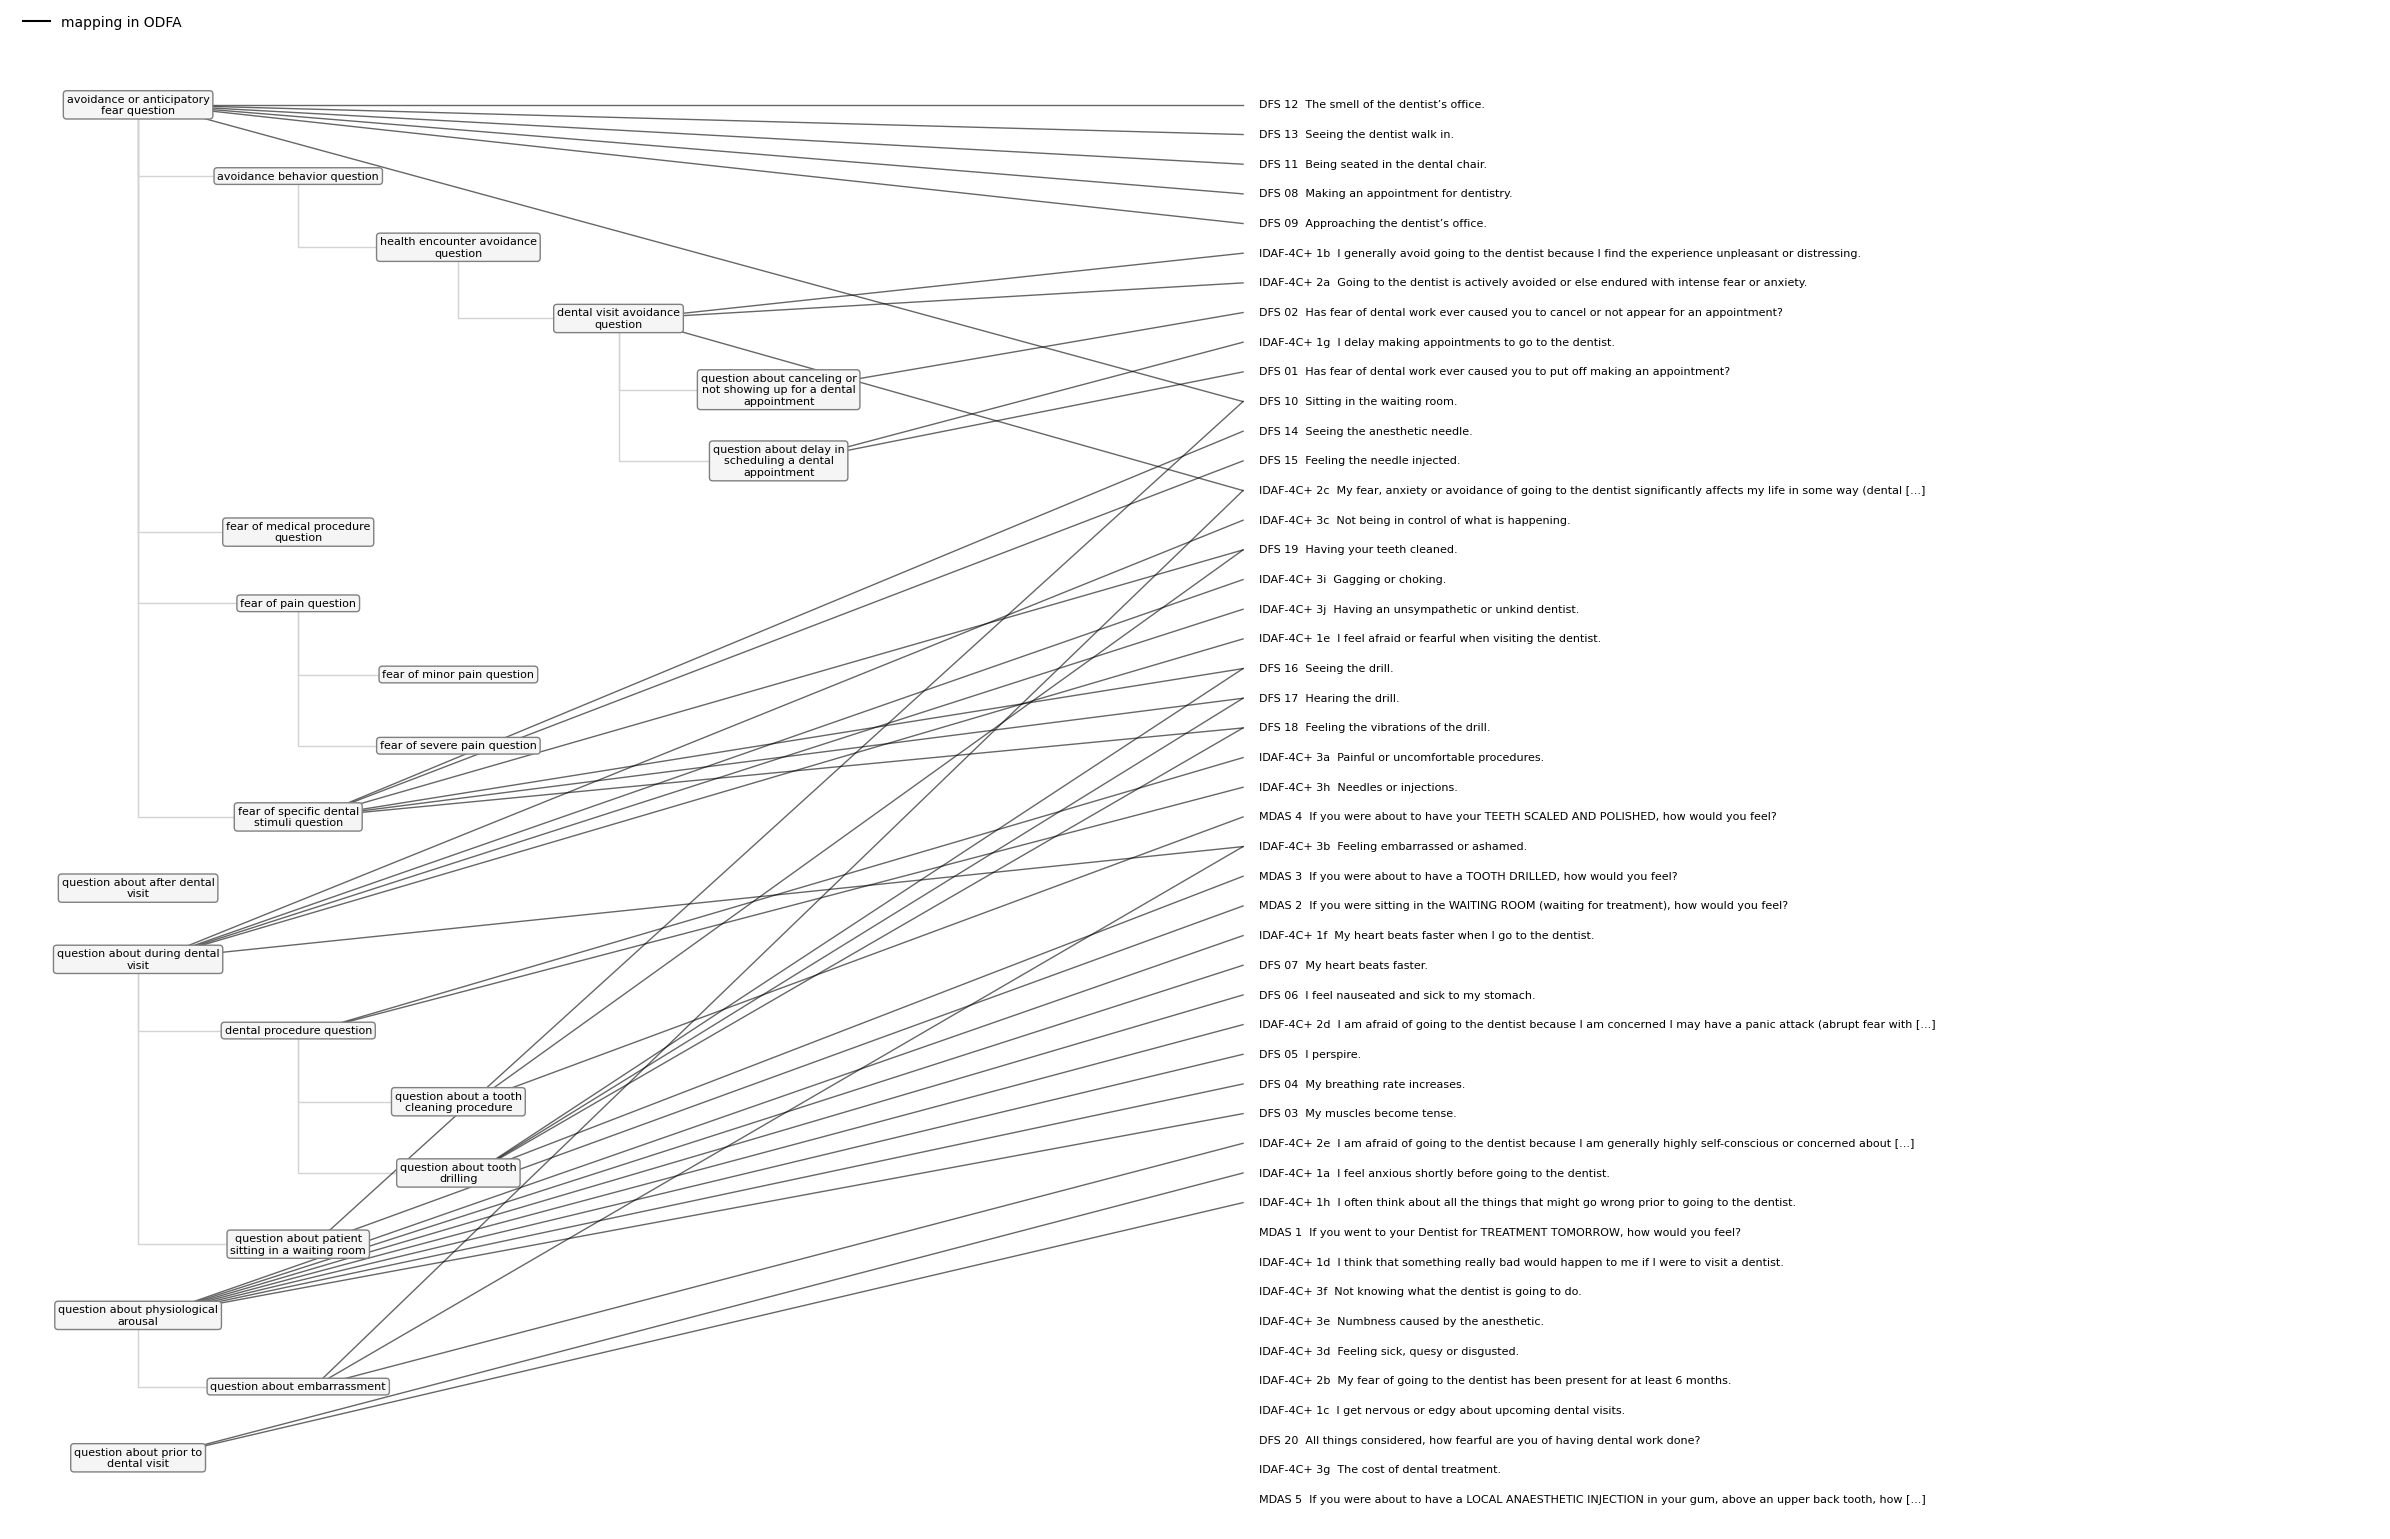

In [20]:
# 3. Visualization of the original ontology
plot_placements(node_table, item_table, out_file='figures/ontology_original.png')

## 3. Running the LLM mapping
to run a new V4, set `RUN_VERSIONS = ['V4']`; else, leave it as `[]` and no API call is made.

In [21]:
RUN_VERSIONS = []  # leave empty to skip or specify the prompt versions to run e.g., ['V4']

if RUN_VERSIONS:
    MODEL = 'claude-sonnet-4-5-20250929'  

    if 'ANTHROPIC_API_KEY' not in os.environ:
        os.environ['ANTHROPIC_API_KEY'] = getpass('Anthropic API key: ')

    for version in RUN_VERSIONS:
        place_items(item_table, node_table, PROMPTS[version], MODEL, RESULTS[version])

In [22]:
# Display all prompt versions
for version, prompt in PROMPTS.items():
    print(f'\n{"=" * 20} {version} {"=" * 20}\n')
    print(prompt)


==================== V1 ====================

You are mapping questionnaire items to classes in the Ontology of Dental Care-Related Fear and Anxiety (ODFA).

Below is the complete set of ODFA question classes available for this task. Each line gives a class ID, its label, and its definition. Indentation indicates parent-child relations.

{tree}

Questionnaire item:
{item}

Identify the most appropriate existing ODFA class or classes for this item. Choose the most specific class when possible. An item may map to more than one class.

If no existing class adequately captures the item's content, propose one new class and identify its most appropriate parent class.

Return only valid JSON:
{{
  "nodes": ["<class id>", ...],
  "new_node": null or {{
    "label": "<new class label>",
    "definition": "<new class definition>",
    "parent_id": "<existing class id or null>"
  }},
  "rationale": "<one short sentence>"
}}

==================== V2 ====================

You are mapping questionn


V1 - ontology_claude.jsonl


item_id,nodes,new_node,rationale
DFS 01,question about delay in scheduling a dental appointment (OHD_0008024),—,"The item asks whether dental fear led the respondent to put off making an appointment, which is a delay in scheduling a dental appointment."
DFS 02,question about canceling or not showing up for a dental appointment (OHD_0008023),—,"The item asks whether dental fear led the respondent to cancel or fail to appear for a dental appointment, which matches the canceling or no-show avoidance class exactly."
DFS 03,question about physiological arousal (OHD_0008047),—,"Muscle tension is a change in bodily state in response to a stimulus, so the item fits the physiological arousal class directly."
DFS 04,question about physiological arousal (OHD_0008047),—,"An increased breathing rate is a change in bodily activity in response to a stimulus, so it falls under physiological arousal."
DFS 05,question about physiological arousal (OHD_0008047),question about sweating (Parent: question about physiological arousal),"Perspiring is a physiological arousal response, and a more specific sweating class would sit under physiological arousal."
DFS 06,question about physiological arousal (OHD_0008047),—,"Nausea and stomach upset are a bodily response to a feared stimulus, so the item fits physiological arousal, and no more specific child class covers nausea."
DFS 07,question about physiological arousal (OHD_0008047),—,"A faster heartbeat is a bodily change in response to a stimulus, which fits the physiological arousal question class."
DFS 08,"question about prior to dental visit (OHD_0008041), avoidance or anticipatory fear question (OHD_0008007)",—,"The item asks about fear when making a dental appointment, which is anticipatory fear about something that happens before a dental visit, not about delay or avoidance."
DFS 09,"question about prior to dental visit (OHD_0008041), avoidance or anticipatory fear question (OHD_0008007)",—,"The item asks about fear while approaching the dentist's office, which happens before the dental visit and reflects anticipatory fear."
DFS 10,question about patient sitting in a waiting room (OHD_0008029),—,"The item directly concerns a patient sitting in a waiting room, which matches the existing class for that situation exactly."


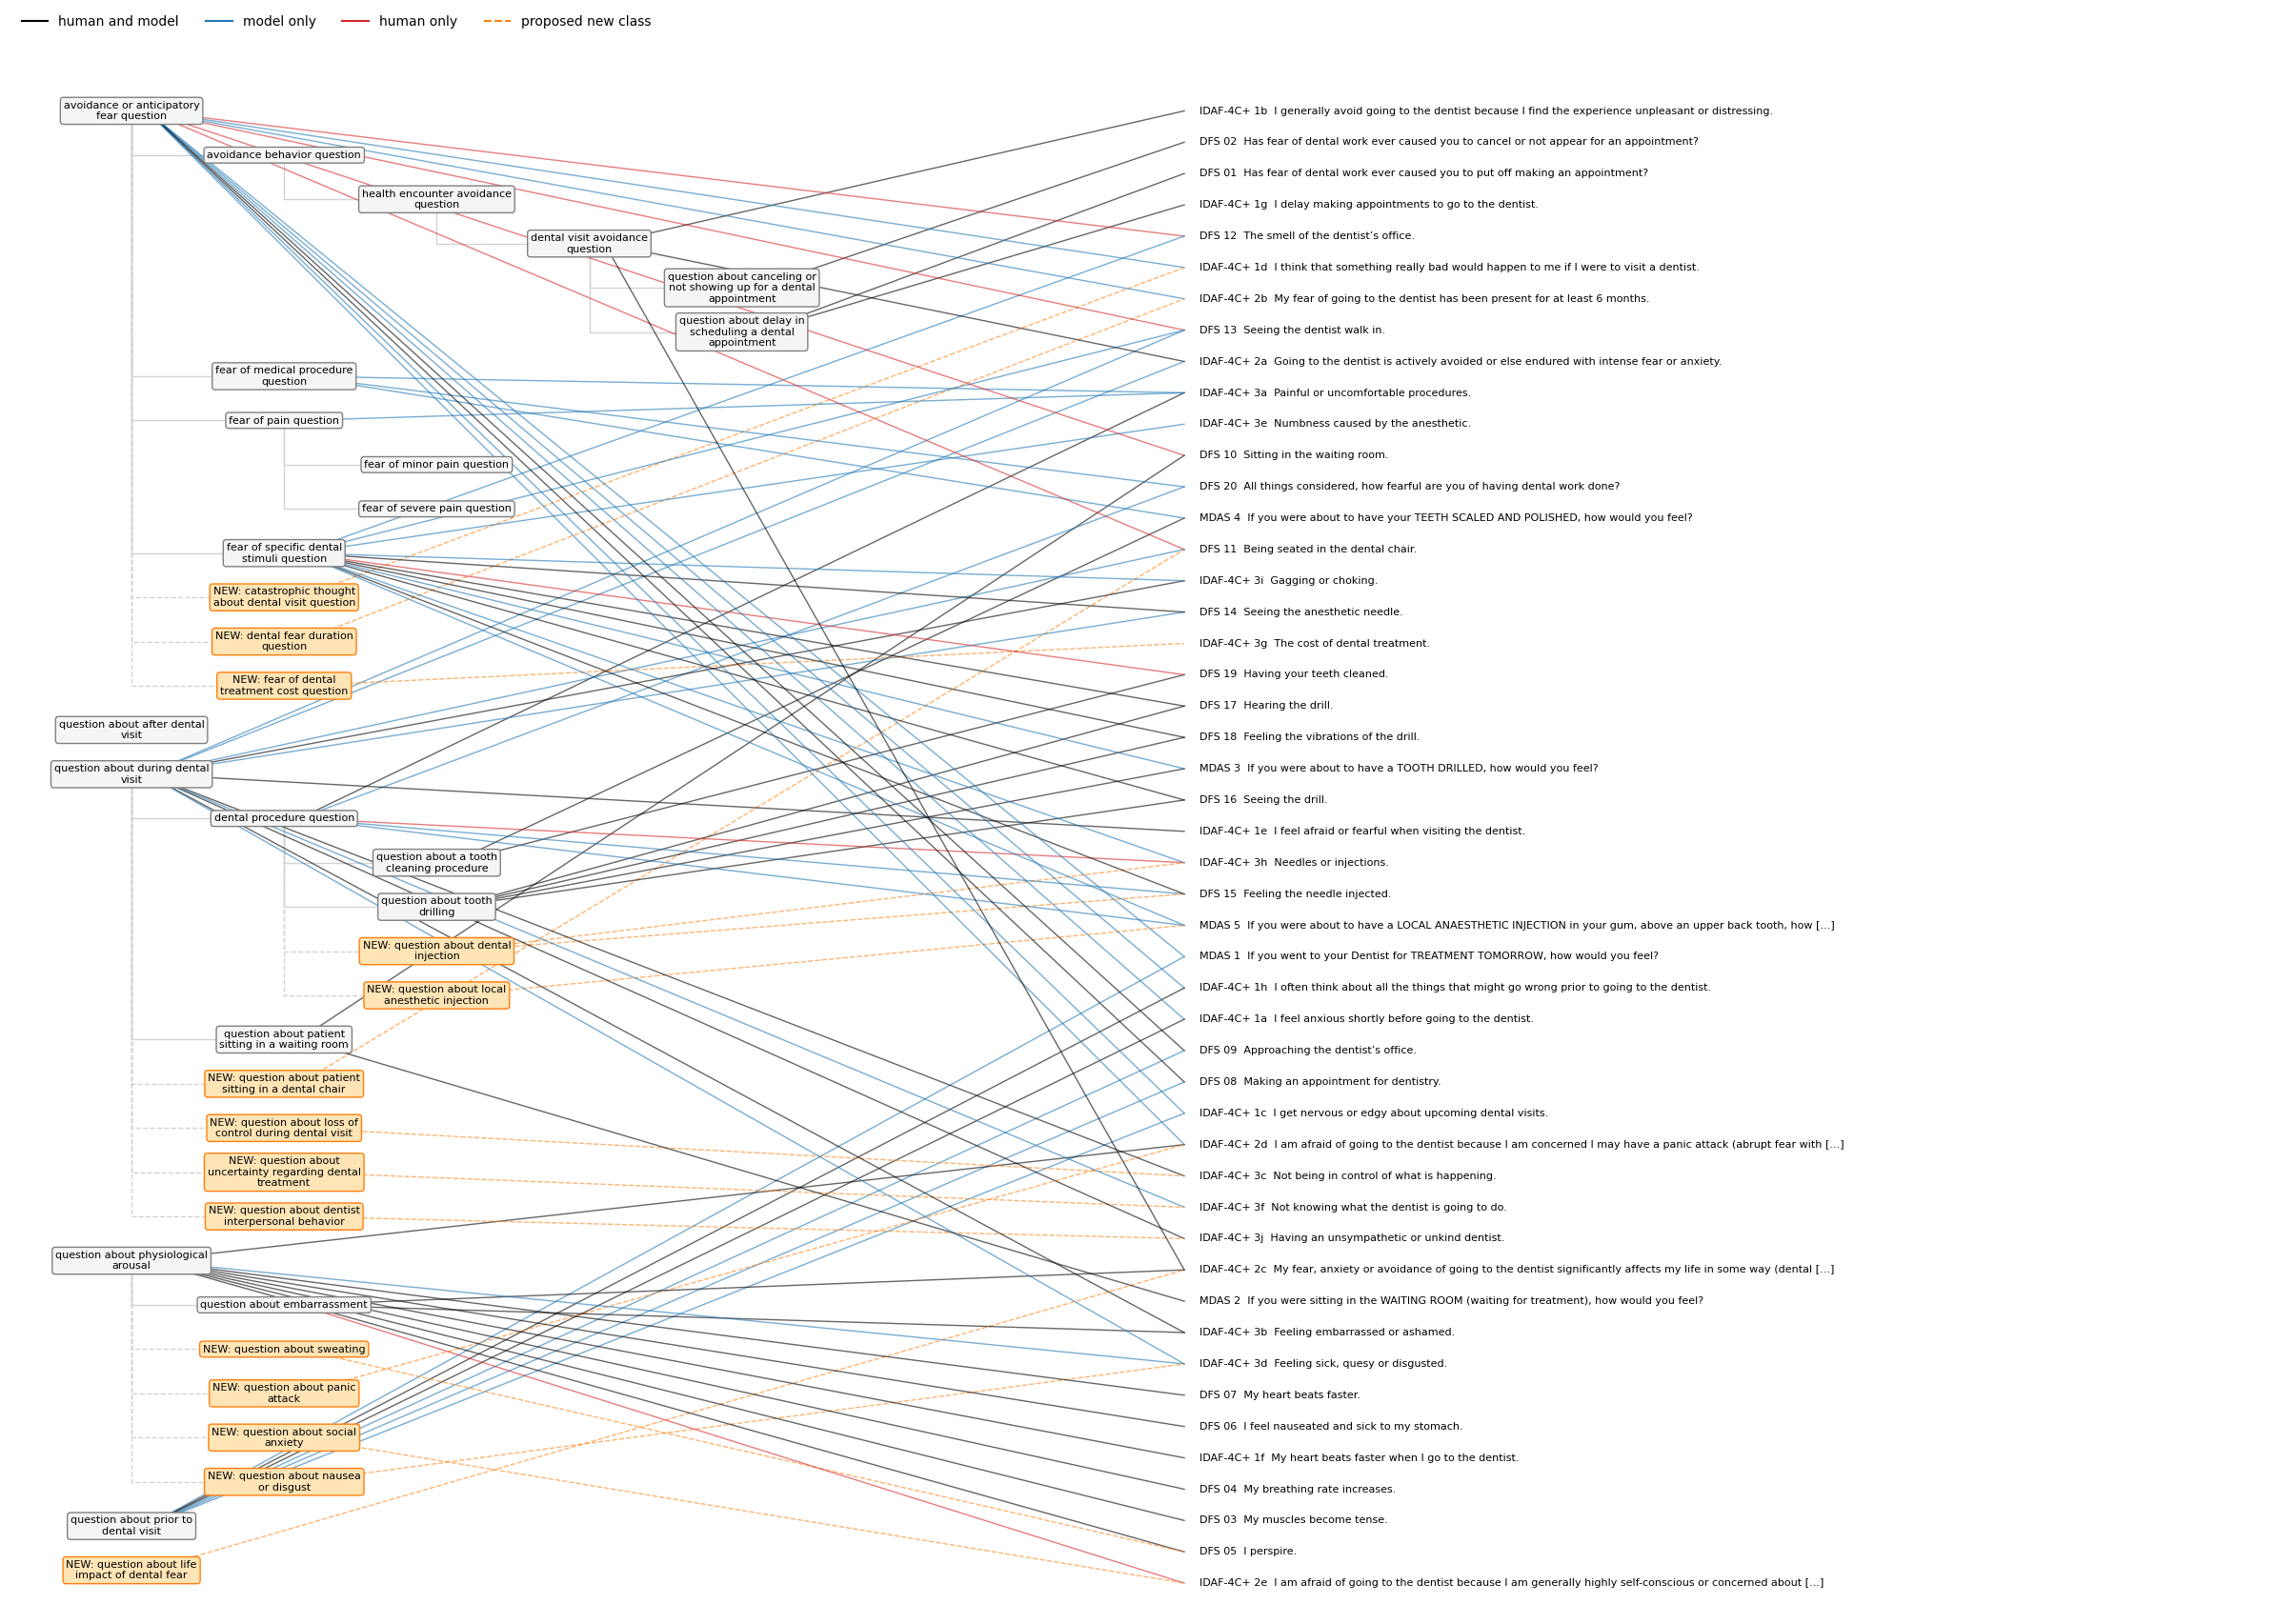


V2 - ontology_claude_v2.jsonl


item_id,nodes,new_node,rationale
DFS 01,"question about delay in scheduling a dental appointment (OHD_0008024), question about prior to dental visit (OHD_0008041)",—,"The item asks whether dental fear led the respondent to put off making an appointment, which is a delay in scheduling that happens before a dental visit."
DFS 02,question about canceling or not showing up for a dental appointment (OHD_0008023),—,"The item asks whether dental fear has led to canceling or failing to appear for a dental appointment, which matches the cancellation/no-show avoidance class."
DFS 03,question about physiological arousal (OHD_0008047),—,"Muscle tension is a bodily change in response to a stimulus, so the item fits the physiological arousal question class; the embarrassment subclass does not apply."
DFS 04,question about physiological arousal (OHD_0008047),—,"An increase in breathing rate is a bodily change in response to a stimulus, so the item is a physiological arousal question; no more specific child class fits."
DFS 05,question about physiological arousal (OHD_0008047),—,"Perspiring is a bodily change in response to a stimulus, so it falls under physiological arousal; no more specific class such as embarrassment applies."
DFS 06,question about physiological arousal (OHD_0008047),—,"Nausea and an upset stomach are bodily changes in response to a stimulus, so the item fits physiological arousal; no more specific child class covers it."
DFS 07,question about physiological arousal (OHD_0008047),—,"A faster heartbeat is a change in bodily state in response to a stimulus, which is physiological arousal; no more specific child class fits."
DFS 08,"question about prior to dental visit (OHD_0008041), avoidance or anticipatory fear question (OHD_0008007)",—,"The item asks about fear when making a dental appointment, which is anticipatory fear about something that happens before a dental visit."
DFS 09,"question about prior to dental visit (OHD_0008041), fear of specific dental stimuli question (OHD_0008046)",—,"The item asks about fear of approaching the dentist's office, which happens before the dental visit and is one of the specific dental-situation stimuli rated in dental fear surveys."
DFS 10,question about patient sitting in a waiting room (OHD_0008029),—,"The item asks directly about a patient sitting in a waiting room, which matches this class exactly."


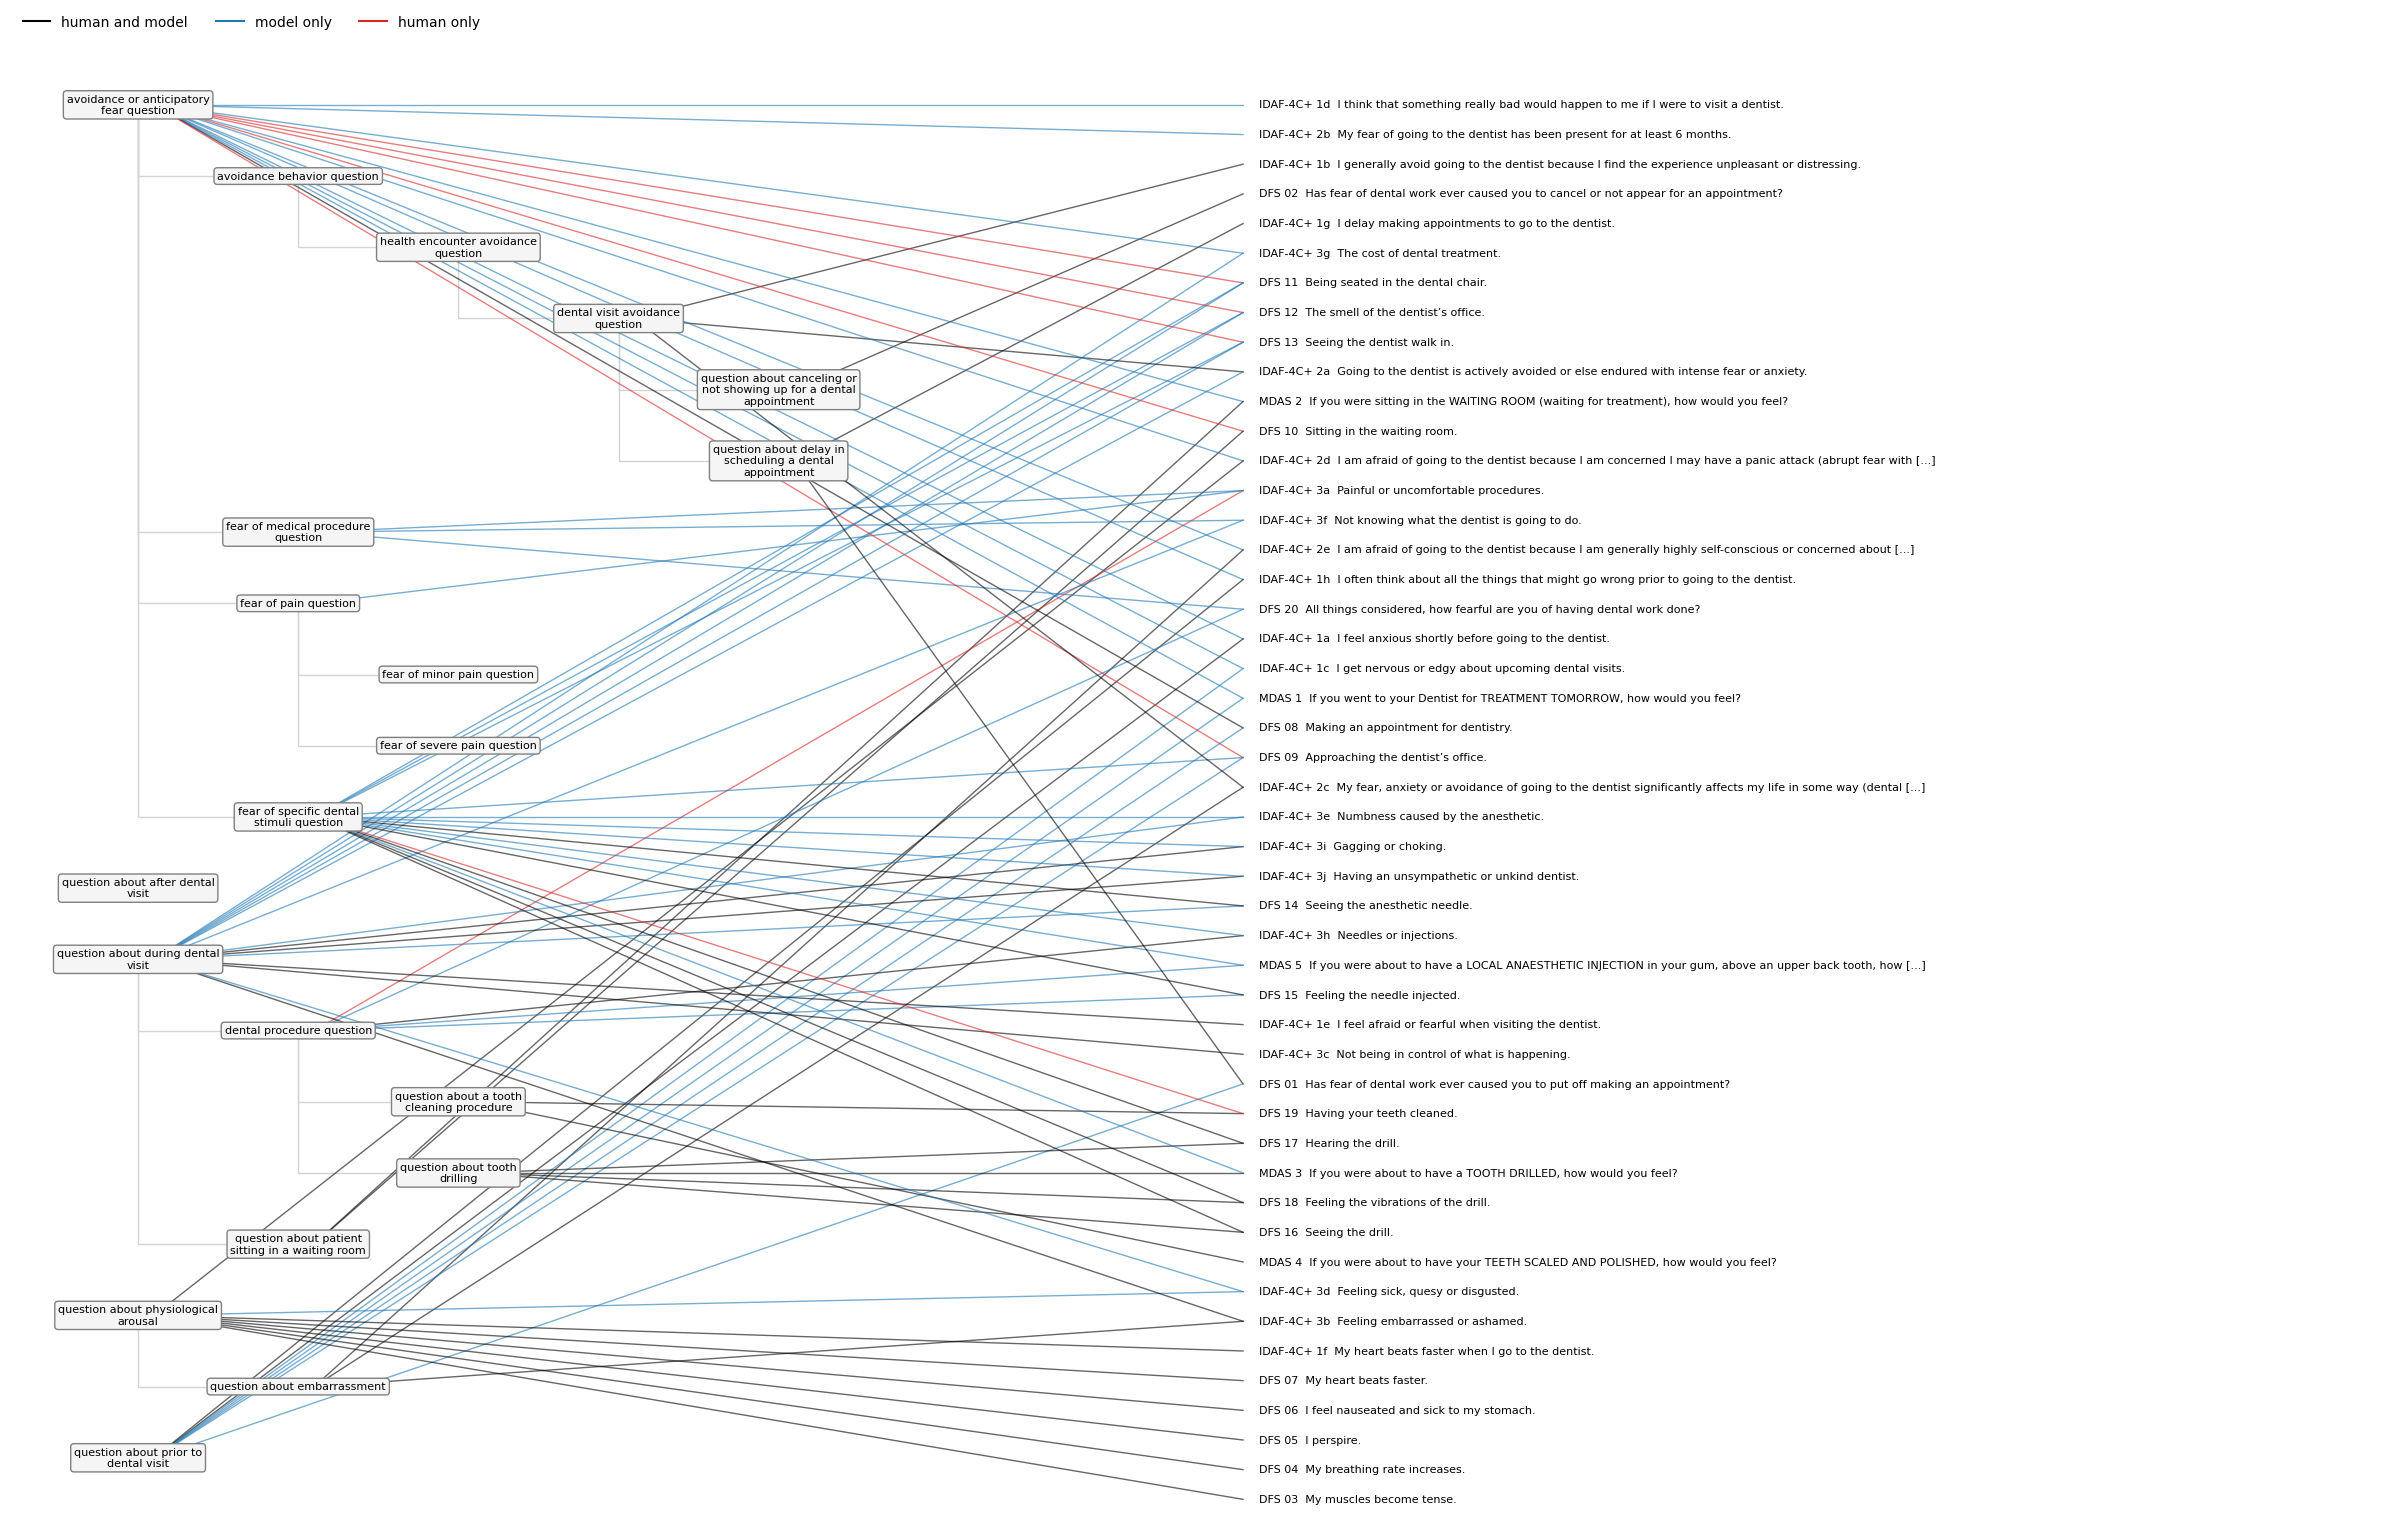


V3 - ontology_claude_v3.jsonl


item_id,nodes,new_node,rationale
DFS 01,question about delay in scheduling a dental appointment (OHD_0008024),—,"The item asks whether dental fear caused the respondent to put off making an appointment, which is a delay in scheduling a dental appointment."
DFS 02,question about canceling or not showing up for a dental appointment (OHD_0008023),—,"The item asks whether fear has led the respondent to cancel or fail to appear for a dental appointment, which matches the cancellation/no-show avoidance class."
DFS 03,question about physiological arousal (OHD_0008047),—,"Tense muscles are a bodily change in response to a stimulus, which is what the physiological arousal question class covers."
DFS 04,question about physiological arousal (OHD_0008047),—,"An increased breathing rate is a change in bodily activity in response to a stimulus, which is the definition of a physiological arousal question."
DFS 05,question about physiological arousal (OHD_0008047),—,"Perspiring is a bodily response to a stimulus, which is exactly what the physiological arousal question class covers."
DFS 06,question about physiological arousal (OHD_0008047),—,"Nausea and feeling sick to one's stomach are bodily state changes in response to a stimulus, so the item fits the physiological arousal question class."
DFS 07,question about physiological arousal (OHD_0008047),—,"A faster heartbeat is a bodily change in response to a stimulus, which is what the physiological arousal question class covers."
DFS 08,question about prior to dental visit (OHD_0008041),—,"Making a dental appointment is an event that happens before a dental visit, and the item asks about the anticipatory experience of it rather than avoidance or delay."
DFS 09,question about prior to dental visit (OHD_0008041),—,"Approaching the dentist's office happens before the dental visit, so the item fits the prior-to-dental-visit class."
DFS 10,question about patient sitting in a waiting room (OHD_0008029),—,"The item directly asks about a patient sitting in a waiting room, which matches the 'question about patient sitting in a waiting room' class exactly."


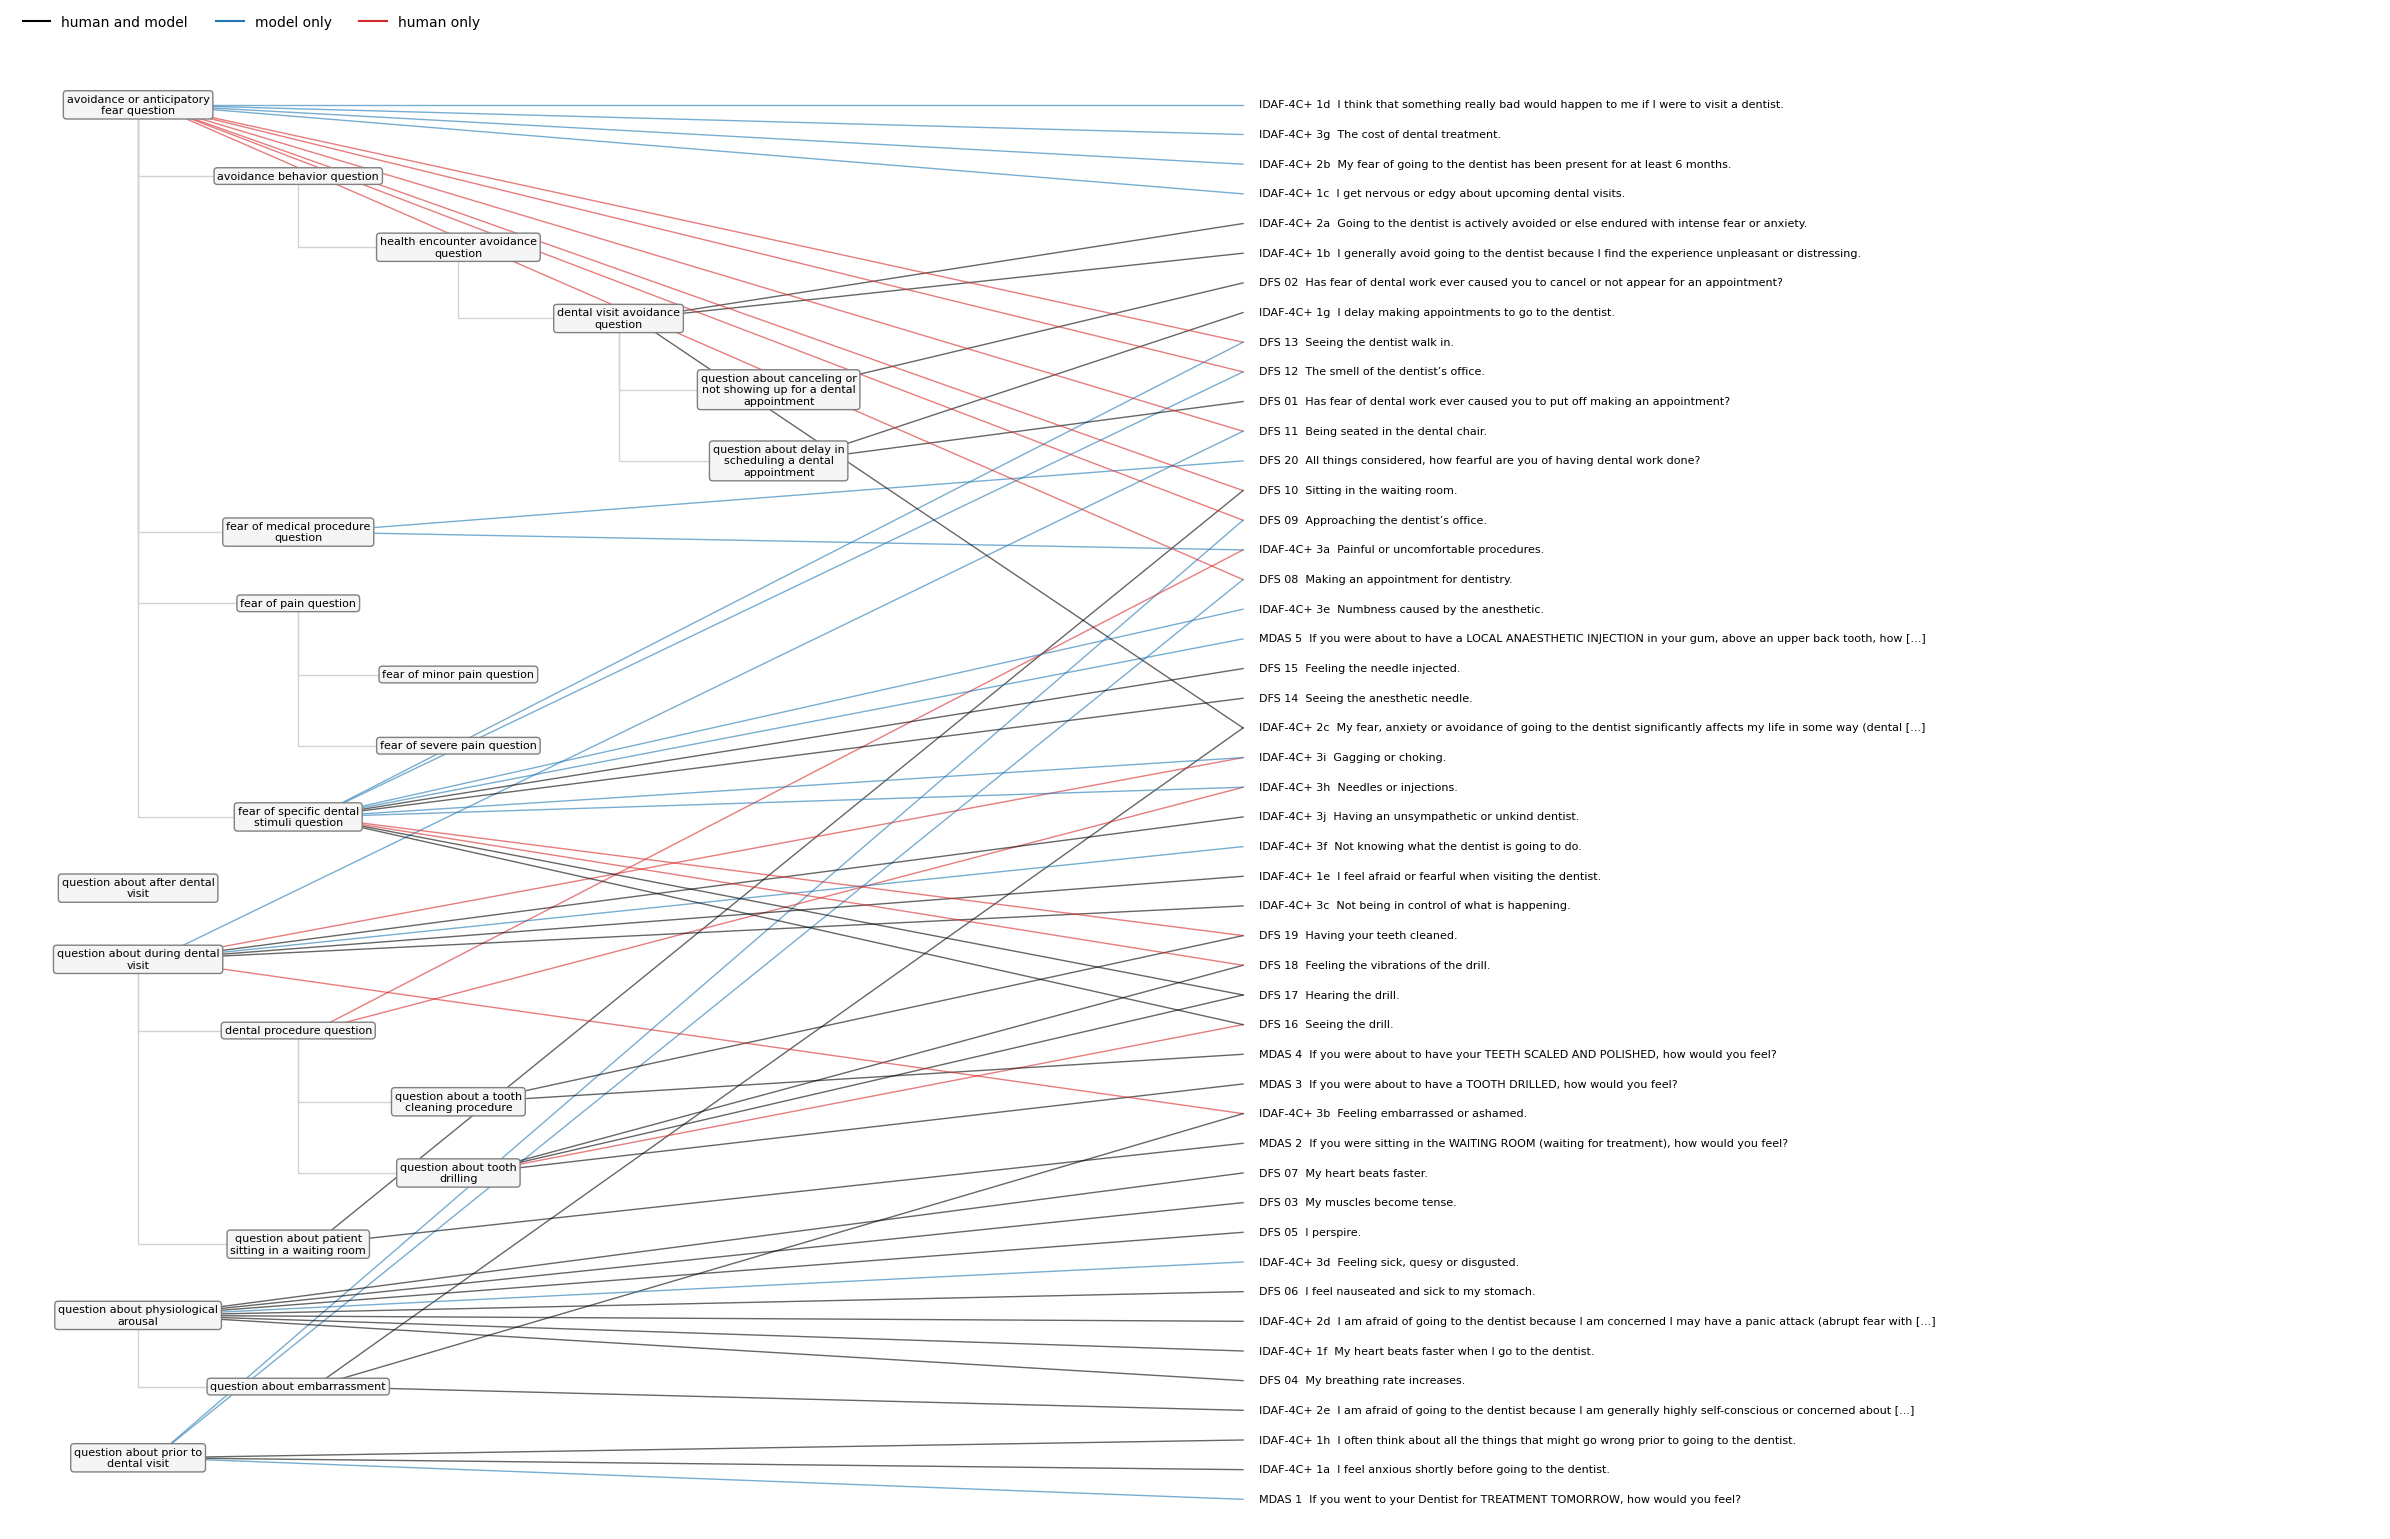

In [23]:
# Load saved mapping results
placements = {v: load_placements(f) for v, f in RESULTS.items() if os.path.exists(f)}
labels = dict(zip(node_table['node_id'], node_table['label']))

for version, p in placements.items():
    print(f'\n{version} - {RESULTS[version]}')
    view = p[['item_id', 'nodes', 'new_node', 'rationale']].copy()

    # Display class names and IDs
    view['nodes'] = view['nodes'].apply(
        lambda ids: ', '.join(f"{labels.get(n, n)} ({n})" for n in ids))
    view['new_node'] = view['new_node'].apply(
        lambda n: f"{n['label']} (Parent: {labels.get(n.get('parent_id'), n.get('parent_id'))})"
        if isinstance(n, dict) else '—')

    # Display the complete table without row indices
    display(HTML(view.to_html(index=False, escape=True)))

    plot_placements(node_table, item_table, p, out_file=f'figures/placement_{version.lower()}.png')

## 4. Evaluation

Compare the classes predicted by the LLM (`nodes`) with the human placement stored in the ontology (`human_nodes`) to evaluate how each prompt version performs.

| Metric | Definition |
|---|---|
| **Exact Match** | Proportion of items whose predicted set of classes is exactly the same as the human set. |
| **Precision** | Proportion of predicted classes that are correct. |
| **Recall** | Proportion of human-assigned classes that the model correctly identified. |
| **F1** | Harmonic mean of Precision and Recall. |
| **Hierarchical Precision (h_precision)** | Precision computed after adding all ancestor classes of the predicted and human classes. |
| **Hierarchical Recall (h_recall)** | Recall computed after adding all ancestor classes of the predicted and human classes. |
| **Hierarchical F1 (h_f1)** | Harmonic mean of Hierarchical Precision and Hierarchical Recall. |

Other columns:

- `n_items`: number of items evaluated.
- `n_human_empty`: number of items with no human-assigned class.
- `n_new_node`: number of items for which the model proposed a new class.
- `model`: the LLM used.

In [24]:
scores = {version: score(p, item_table, node_table) for version, p in placements.items()}
for version, s in scores.items():
    s.to_csv(f'scores/score_{version.lower()}.csv', index=False)

summary = pd.DataFrame({version: summarize(s) for version, s in scores.items()}).T
summary = summary.astype({'n_items': int, 'n_human_empty': int, 'n_new_node': int})
summary['model'] = [p['model'].iloc[0] for p in placements.values()]
summary

,exact_match,precision,recall,f1,h_precision,h_recall,h_f1,n_items,n_human_empty,n_new_node,model
V1,0.417,0.583,0.842,0.599,0.614,0.902,0.638,48,10,15,claude-opus-5-5
V2,0.354,0.542,0.842,0.576,0.588,0.954,0.635,48,10,0,claude-opus-5-5
V3,0.521,0.625,0.724,0.590,0.646,0.788,0.625,48,10,0,claude-opus-5-5
